# WikiArt — reconnaître le style d’un tableau

Un visiteur photographie une peinture. Peut-on en reconnaître le style à partir de l’image ?
On travaille ici sur cinq styles de WikiArt : **Baroque, Cubism, Impressionism, Pop Art et Ukiyo-e**,
avec 300 tableaux par style.

On commence par regarder les données, puis on entraîne un premier réseau dense (MLP).
L’objectif de ce premier essai est d’avoir un point de comparaison et de comprendre ses erreurs.
On compare ensuite plusieurs régularisations du MLP, puis on entraîne la tête d’un ResNet-18 préentraîné.
La comparaison avec un modèle classique viendra plus tard.

Pour relire les résultats, on peut exécuter le notebook avec les réglages ci-dessous.
Les 40 époques du MLP sont déjà enregistrées ; elles ne sont relancées que si `RUN_TRAINING` vaut `True`.
Le noyau à utiliser est **Python (WikiArt)** ; l’installation est décrite dans le [README](README.md).


## Réglages de l’expérience

Les paramètres que l’on peut changer sont regroupés ici. On garde deux seeds distinctes :
0 pour choisir les images de WikiArt, 42 pour le découpage et l’entraînement.
Après un changement, on réexécute le notebook depuis le début.


In [1]:
from __future__ import annotations

import csv
import hashlib
import io
import json
import os
import random
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image
from torch import nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms


In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").is_file():
    raise RuntimeError("Ouvrir le notebook depuis la racine du dépôt WikiArt.")

DATA_DIR = ROOT / "data/wikiart_style5"
MANIFEST_DIR = ROOT / "manifests"
MANIFEST_PATH = MANIFEST_DIR / "wikiart_style5_seed42.csv"
OUTPUT_DIR = ROOT / "outputs/mlp_baseline"
CLASSES = ["Impressionism", "Baroque", "Cubism", "Ukiyo_e", "Pop_Art"]
DOWNLOAD_DATA = False  # True pour télécharger les images ou reprendre un téléchargement
RUN_TRAINING = False  # True pour relancer le MLP ; sinon, on relit les résultats
RUN_REGULARIZATION = False  # True pour relancer les cinq essais du MLP
RUN_RESNET_HEAD = False  # True pour extraire les caractéristiques et entraîner la tête
SEED = 42

REPO = "huggan/wikiart"
REVISION = "d559852d2b232e0fcf195e775866964f0564f2b5"
LABEL_COLUMNS = ("style", "genre", "artist")
UNKNOWN_ARTIST = "Unknown Artist"
GB_PER_SHARD = 33.74 / 72

DOWNLOAD_CONFIG = SimpleNamespace(
    label="style", classes=CLASSES, per_class=300, size=128, no_crop=False,
    out=DATA_DIR, seed=0, strategy="fewest-shards", max_per_artist=50,
    quality=90, revision=REVISION, index_cache=None, retries=3,
    list_classes=False, dry_run=False,
)
MLP_CONFIG = SimpleNamespace(
    data=DATA_DIR, manifest=MANIFEST_PATH, output_dir=OUTPUT_DIR,
    seed=SEED, batch_size=64, epochs=40, learning_rate=1e-3,
    workers=0, device="auto",
)


## 1. D’où viennent les images ?

On utilise un sous-ensemble de `huggan/wikiart`, avec une révision fixée pour pouvoir retrouver les mêmes données.
Les images sont converties en RGB, recadrées au centre et enregistrées en 128 × 128 pixels.
Le plafond est de 50 images par artiste nommé ; `Unknown Artist` regroupe plusieurs artistes inconnus et n’est pas plafonné.

Le téléchargement passe par neuf shards, soit environ 4,2 Go. Si les images sont déjà dans `data/wikiart_style5`,
on les réutilise. Sur un nouveau clone, il faut d’abord mettre `DOWNLOAD_DATA = True`.

Les fonctions de récupération sont repliées ci-dessous pour laisser plus de place à l’étude.
Elles gardent l’index des étiquettes en cache et permettent de reprendre un téléchargement interrompu.
Les images restent en local : la licence du jeu est indiquée comme inconnue.


In [3]:
def log(msg: str = "") -> None:
    print(msg, flush=True)


def open_stream(revision: str, columns=None):
    """The whole dataset as a streaming IterableDataset (optionally only some columns)."""
    from datasets import load_dataset
    kwargs = {"columns": list(columns)} if columns else {}
    return load_dataset(REPO, split="train", streaming=True, revision=revision, **kwargs)


def with_retries(fn, what: str, retries: int):
    for attempt in range(1, retries + 1):
        try:
            return fn()
        except KeyboardInterrupt:
            raise
        except Exception as e:  # network hiccups: retry with a growing pause
            if attempt == retries:
                raise
            wait = 10 * attempt
            log(f"  ! {what}: {type(e).__name__}: {str(e)[:160]} -> retry {attempt}/{retries - 1} in {wait} s")
            time.sleep(wait)


def default_index_path(revision: str) -> Path:
    return Path.home() / ".cache" / f"wikiart_label_index_{revision[:12]}.json"


def load_label_index(revision: str, cache: Path, retries: int) -> dict:
    """{'names': {label: [class names]}, 'shards': [{'style': [...], 'genre': [...], 'artist': [...]}, ...]}"""
    if cache.exists():
        index = json.loads(cache.read_text(encoding="utf-8"))
        if index.get("revision") == revision:
            log(f"Label index: {cache} ({sum(len(s['style']) for s in index['shards'])} rows, cached)")
            return index
    log("Label pass: streaming the label columns of every shard (no images, a few KB each)...")
    t0 = time.time()
    ds = with_retries(lambda: open_stream(revision, LABEL_COLUMNS), "load_dataset", retries)
    names = {k: list(ds.features[k].names) for k in LABEL_COLUMNS}
    shards = []
    for i in range(ds.n_shards):
        def read_shard(i=i):
            cols = {k: [] for k in LABEL_COLUMNS}
            for ex in ds.shard(num_shards=ds.n_shards, index=i):
                for k in LABEL_COLUMNS:
                    cols[k].append(ex[k])
            return cols
        shards.append(with_retries(read_shard, f"labels of shard {i}", retries))
        if (i + 1) % 12 == 0 or i + 1 == ds.n_shards:
            log(f"  {i + 1}/{ds.n_shards} shards indexed ({time.time() - t0:.0f} s)")
    index = {"repo": REPO, "revision": revision, "names": names, "shards": shards}
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(index), encoding="utf-8")
    log(f"Label index saved to {cache}")
    return index


In [4]:
def _norm(name: str) -> str:
    return name.lower().replace("-", "_").replace(" ", "_")


def resolve_classes(requested, names):
    lookup = {_norm(n): i for i, n in enumerate(names)}
    ids = []
    for r in requested:
        if _norm(r) not in lookup:
            sys.exit(f"Unknown class {r!r}. Valid names: {', '.join(names)}")
        if lookup[_norm(r)] not in ids:
            ids.append(lookup[_norm(r)])
    return ids


def list_classes(index: dict, label: str) -> None:
    names, shards = index["names"], index["shards"]
    unknown = names["artist"].index(UNKNOWN_ARTIST) if UNKNOWN_ARTIST in names["artist"] else -1
    count, n_shards, artists, unk = Counter(), Counter(), {}, Counter()
    for s in shards:
        seen = set()
        for c, a in zip(s[label], s["artist"]):
            count[c] += 1
            seen.add(c)
            artists.setdefault(c, set()).add(a)
            unk[c] += a == unknown
        for c in seen:
            n_shards[c] += 1
    log(f"\n{label} classes of {REPO} ({sum(count.values())} images):")
    log(f"  {'name':28s} {'images':>7s} {'shards':>7s} {'named artists':>14s} {'unknown artist':>15s}")
    for c, n in count.most_common():
        named = len(artists[c] - {unknown})
        log(f"  {names[label][c]:28s} {n:7d} {n_shards[c]:7d} {named:14d} {unk[c] / n:14.0%}")


def make_plan(index: dict, label: str, class_ids, per_class: int, max_per_artist: int, strategy: str, seed: int):
    """Choose the rows to download: returns ({shard: [rows]}, {class_id: still missing})."""
    names, shards = index["names"], index["shards"]
    unknown = names["artist"].index(UNKNOWN_ARTIST) if UNKNOWN_ARTIST in names["artist"] else -1
    rng = random.Random(seed)
    wanted = set(class_ids)
    candidates = {}
    for s, cols in enumerate(shards):
        rows = [r for r, c in enumerate(cols[label]) if c in wanted]
        rng.shuffle(rows)  # which rows of a shard are taken is random but reproducible
        candidates[s] = rows
    order = list(range(len(shards)))
    rng.shuffle(order)
    need = {c: per_class for c in class_ids}
    per_artist = Counter()

    def rows_from(s):
        """Rows that shard s would add, given what has already been planned (no side effect)."""
        need2, art2, take = dict(need), Counter(), []
        for r in candidates[s]:
            c, a = shards[s][label][r], shards[s]["artist"][r]
            if need2[c] == 0:
                continue
            if max_per_artist and a != unknown and per_artist[a] + art2[a] >= max_per_artist:
                continue
            take.append(r)
            need2[c] -= 1
            art2[a] += 1
        return take

    plan, remaining = {}, list(order)
    while any(need.values()) and remaining:
        if strategy == "fewest-shards":
            best = max(remaining, key=lambda s: len(rows_from(s)))  # ties: first in the seeded order
        else:
            best = next((s for s in remaining if rows_from(s)), remaining[0])
        take = rows_from(best)
        remaining.remove(best)
        if not take:
            break
        plan[best] = sorted(take)
        for r in take:
            need[shards[best][label][r]] -= 1
            per_artist[shards[best]["artist"][r]] += 1
    return plan, need


def print_plan(plan, need, index, label, class_ids, per_class):
    names, shards = index["names"], index["shards"]
    got = Counter(shards[s][label][r] for s, rows in plan.items() for r in rows)
    artists = Counter(shards[s]["artist"][r] for s, rows in plan.items() for r in rows)
    log(f"\nPlan: {len(plan)} shard(s) to stream (~{len(plan) * GB_PER_SHARD:.1f} GB): {sorted(plan)}")
    for c in class_ids:
        flag = "" if got[c] == per_class else f"   <- only {got[c]} available with these settings"
        log(f"  {names[label][c]:28s} {got[c]:5d} images{flag}")
    top = [(names["artist"][a], n) for a, n in artists.most_common(6)]
    log(f"  most frequent artists in the subset: {top}")
    if any(need.values()):
        log("  Warning: some classes are incomplete (try another seed, --max-per-artist 0 or fewer images).")


In [5]:
def save_image(data: bytes, dst: Path, size: int, crop: bool, quality: int):
    from PIL import Image, ImageOps
    Image.MAX_IMAGE_PIXELS = None  # some WikiArt scans are very large (trusted source)
    with Image.open(io.BytesIO(data)) as im:
        orig = im.size
        im.draft("RGB", (size, size))  # fast JPEG decoding at reduced scale (never below the requested size)
        im = im.convert("RGB")
        if crop:
            im = ImageOps.fit(im, (size, size), method=Image.Resampling.BICUBIC)
        else:
            w, h = im.size
            scale = size / min(w, h)
            im = im.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.Resampling.BICUBIC)
        tmp = dst.with_name(dst.name + ".part")
        im.save(tmp, "JPEG", quality=quality)
        tmp.replace(dst)
    return orig


def row_id(shard: int, row: int) -> str:
    return f"s{shard:02d}_r{row:04d}"


def download(plan, index, label, class_names, args, sizes):
    """Stream the planned shards and save the selected images; returns {row_id: (w, h)}."""
    from datasets import Image as HFImage
    shards = index["shards"]
    todo = {}
    for s, rows in plan.items():
        missing = [r for r in rows
                   if not (args.out / class_names[shards[s][label][r]] / f"{row_id(s, r)}.jpg").exists()]
        if missing:
            todo[s] = missing
    done_already = sum(len(r) for r in plan.values()) - sum(len(r) for r in todo.values())
    if done_already:
        log(f"Resuming: {done_already} images already on disk.")
    if not todo:
        return sizes
    log(f"Image pass: {len(todo)} shard(s) to stream. Each shard arrives in one block (~{GB_PER_SHARD:.2f} GB).")
    ds = with_retries(lambda: open_stream(args.revision), "load_dataset", args.retries)
    ds = ds.cast_column("image", HFImage(decode=False))  # raw bytes: decode only what we keep
    n_shards = ds.n_shards
    for k, (s, rows) in enumerate(sorted(todo.items()), 1):
        t0 = time.time()
        wanted = set(rows)

        def stream_shard(s=s, wanted=wanted):
            left = set(wanted)
            for r, ex in enumerate(ds.shard(num_shards=n_shards, index=s)):
                if r not in left:
                    continue
                c = shards[s][label][r]
                if ex[label] != c:  # safety net: the index must describe this exact revision
                    raise RuntimeError(f"label mismatch at shard {s}, row {r}: delete the index cache and retry")
                dst = args.out / class_names[c] / f"{row_id(s, r)}.jpg"
                sizes[row_id(s, r)] = save_image(ex["image"]["bytes"], dst, args.size, not args.no_crop, args.quality)
                left.discard(r)
                if not left:
                    break
            if left:
                raise RuntimeError(f"shard {s}: {len(left)} planned rows were not found")

        with_retries(stream_shard, f"shard {s}", args.retries)
        log(f"  shard {s:2d} ({k}/{len(todo)}): {len(rows):4d} images saved in {time.time() - t0:5.0f} s")
    return sizes


In [6]:
def write_metadata(plan, index, label, class_ids, class_names, args, sizes) -> Counter:
    names, shards = index["names"], index["shards"]
    folder_order = sorted(class_names[c] for c in class_ids)  # = ImageFolder's class_to_idx
    label_idx = {n: i for i, n in enumerate(folder_order)}
    rows_out, counts = [], Counter()
    for s in sorted(plan):
        for r in plan[s]:
            c = shards[s][label][r]
            rel = f"{class_names[c]}/{row_id(s, r)}.jpg"
            if not (args.out / rel).exists():
                continue
            w, h = sizes.get(row_id(s, r), ("", ""))
            counts[class_names[c]] += 1
            rows_out.append({
                "path": rel, "label": class_names[c], "label_idx": label_idx[class_names[c]], "id": row_id(s, r),
                "style": names["style"][shards[s]["style"][r]], "genre": names["genre"][shards[s]["genre"][r]],
                "artist": names["artist"][shards[s]["artist"][r]], "shard": s, "row": r,
                "orig_width": w, "orig_height": h})
    rows_out.sort(key=lambda d: (d["label_idx"], d["id"]))
    with open(args.out / "metadata.csv", "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows_out[0]) if rows_out else ["path"])
        wr.writeheader()
        wr.writerows(rows_out)
    info = {
        "repo": REPO, "revision": args.revision, "label": label, "classes": folder_order,
        "per_class": args.per_class, "size": args.size, "crop": not args.no_crop, "seed": args.seed,
        "strategy": args.strategy, "max_per_artist": args.max_per_artist, "shards": sorted(plan),
        "counts": {n: counts[n] for n in folder_order}, "total": sum(counts.values()),
        "notebook": "wikiart.ipynb",
        "configuration": {key: str(value) if isinstance(value, Path) else value
                          for key, value in vars(args).items()},
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    (args.out / "subset_info.json").write_text(json.dumps(info, indent=2), encoding="utf-8")
    return counts


def previous_sizes(out: Path) -> dict:
    """Original sizes recorded by a previous (interrupted) run, so that resuming keeps them."""
    meta = out / "metadata.csv"
    if not meta.exists():
        return {}
    with open(meta, newline="", encoding="utf-8") as f:
        return {d["id"]: (d.get("orig_width", ""), d.get("orig_height", "")) for d in csv.DictReader(f)}


In [7]:
def prepare_subset(args: SimpleNamespace) -> int:
    cache = args.index_cache or default_index_path(args.revision)
    index = load_label_index(args.revision, cache, args.retries)
    if args.list_classes:
        list_classes(index, args.label)
        return 0
    names = index["names"][args.label]
    class_ids = resolve_classes(args.classes, names)
    class_names = {c: names[c] for c in class_ids}
    plan, need = make_plan(index, args.label, class_ids, args.per_class, args.max_per_artist, args.strategy, args.seed)
    print_plan(plan, need, index, args.label, class_ids, args.per_class)
    if args.dry_run:
        return 0
    for c in class_ids:
        (args.out / class_names[c]).mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    sizes = download(plan, index, args.label, class_names, args, previous_sizes(args.out))
    counts = write_metadata(plan, index, args.label, class_ids, class_names, args, sizes)
    log(f"\nDone in {time.time() - t0:.0f} s: {sum(counts.values())} images in {args.out.resolve()}")
    log("  " + ", ".join(f"{n}: {k}" for n, k in sorted(counts.items())))
    log(f"  metadata: {args.out / 'metadata.csv'} | reproducibility: {args.out / 'subset_info.json'}")
    complete = all(counts[class_names[c]] >= args.per_class for c in class_ids)
    return 0 if complete else 2


In [8]:
if DOWNLOAD_DATA:
    os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "1800")
    os.environ.setdefault("HF_XET_HIGH_PERFORMANCE", "1")
    status = prepare_subset(DOWNLOAD_CONFIG)
    if status != 0:
        raise RuntimeError("Le téléchargement n'a pas produit toutes les images demandées.")
elif not (DATA_DIR / "metadata.csv").is_file() or not (DATA_DIR / "subset_info.json").is_file():
    raise FileNotFoundError(
        "Données absentes : passer DOWNLOAD_DATA = True dans la configuration, "
        "puis réexécuter les cellules depuis le début."
    )
else:
    print("Sous-ensemble existant réutilisé :", DATA_DIR.relative_to(ROOT))


Sous-ensemble existant réutilisé : data/wikiart_style5


## 2. Vérifier les données avant d’entraîner

On vérifie que les métadonnées correspondent aux fichiers, que les images s’ouvrent correctement
et qu’elles ont toutes le format attendu. On compare aussi les empreintes des fichiers pour repérer les doublons exacts :
une même image dans deux partitions pourrait fausser l’évaluation.

Le découpage se fait par style, avec **70 % pour l’entraînement, 15 % pour la validation et 15 % pour le test**.
La validation sert à choisir les poids que l’on garde. Le test sera utilisé à la fin, après le choix des modèles.
L’inspection ouvre les fichiers de toutes les partitions pour les contrôler, mais le MLP ne charge que train et validation.


In [9]:
def inspect_and_read(data_dir: Path) -> tuple[list[dict[str, str]], dict[str, object]]:
    metadata_path = data_dir / "metadata.csv"
    subset_info_path = data_dir / "subset_info.json"
    if not metadata_path.is_file() or not subset_info_path.is_file():
        raise FileNotFoundError(f"Expected metadata.csv and subset_info.json under {data_dir}")

    rows = list(csv.DictReader(metadata_path.open(encoding="utf-8", newline="")))
    subset_info = json.loads(subset_info_path.read_text(encoding="utf-8"))
    classes = sorted({row["label"] for row in rows})
    class_to_idx = {name: index for index, name in enumerate(classes)}
    errors: dict[str, list[str]] = {
        "duplicate_metadata_paths": [],
        "missing_images": [],
        "unlisted_images": [],
        "label_or_index_mismatches": [],
        "corrupt_images": [],
        "wrong_dimensions": [],
        "wrong_modes": [],
        "wrong_formats": [],
    }

    relative_paths = [row["path"] for row in rows]
    path_counts = Counter(relative_paths)
    errors["duplicate_metadata_paths"] = sorted(path for path, count in path_counts.items() if count > 1)
    listed_paths = set(relative_paths)
    disk_paths = {
        path.relative_to(data_dir).as_posix()
        for path in data_dir.glob("*/*.jpg")
        if path.is_file()
    }
    errors["missing_images"] = sorted(listed_paths - disk_paths)
    errors["unlisted_images"] = sorted(disk_paths - listed_paths)

    class_counts = Counter(row["label"] for row in rows)
    format_counts: Counter[str] = Counter()
    dimension_counts: Counter[str] = Counter()
    mode_counts: Counter[str] = Counter()
    content_hashes: dict[str, list[str]] = defaultdict(list)

    for row in rows:
        rel_path = Path(row["path"])
        expected_idx = class_to_idx.get(row["label"])
        if (
            rel_path.is_absolute()
            or ".." in rel_path.parts
            or row["label"] not in class_to_idx
            or row["label_idx"] != str(expected_idx)
            or rel_path.parts[0] != row["label"]
        ):
            errors["label_or_index_mismatches"].append(row["path"])

        image_path = data_dir / rel_path
        if not image_path.is_file():
            continue
        try:
            with Image.open(image_path) as image:
                image.load()
                format_name = image.format or "unknown"
                size = image.size
                mode = image.mode
            format_counts[format_name] += 1
            dimension_counts[f"{size[0]}x{size[1]}"] += 1
            mode_counts[mode] += 1
            if size != (128, 128):
                errors["wrong_dimensions"].append(row["path"])
            if mode != "RGB":
                errors["wrong_modes"].append(row["path"])
            if format_name != "JPEG":
                errors["wrong_formats"].append(row["path"])
            content_hashes[hashlib.sha256(image_path.read_bytes()).hexdigest()].append(row["path"])
        except Exception as error:  # Keep the offending path in the quality report.
            errors["corrupt_images"].append(f"{row['path']}: {type(error).__name__}: {error}")

    duplicate_content = [paths for paths in content_hashes.values() if len(paths) > 1]
    artist_counts = Counter(row.get("artist", UNKNOWN_ARTIST) for row in rows)
    report: dict[str, object] = {
        "dataset": {
            "repo": subset_info["repo"],
            "revision": subset_info["revision"],
            "label": subset_info["label"],
            "classes": classes,
            "class_to_idx": class_to_idx,
            "metadata_rows": len(rows),
            "image_files": len(disk_paths),
            "class_counts": dict(sorted(class_counts.items())),
        },
        "image_integrity": {
            "format_counts": dict(sorted(format_counts.items())),
            "dimension_counts": dict(sorted(dimension_counts.items())),
            "mode_counts": dict(sorted(mode_counts.items())),
            "exact_duplicate_groups": len(duplicate_content),
            "exact_duplicate_images": sum(len(paths) for paths in duplicate_content),
            "errors": errors,
        },
        "artist_coverage": {
            "unknown_artist_images": artist_counts.get(UNKNOWN_ARTIST, 0),
            "unknown_artist_fraction": artist_counts.get(UNKNOWN_ARTIST, 0) / max(1, len(rows)),
            "named_artist_count": len([artist for artist in artist_counts if artist != UNKNOWN_ARTIST]),
        },
    }

    class_counts_match = all(class_counts[name] == subset_info["per_class"] for name in classes)
    report["image_integrity"]["class_counts_match_subset_plan"] = class_counts_match
    error_count = sum(len(values) for values in errors.values())
    if error_count or not class_counts_match or len(disk_paths) != len(rows):
        raise ValueError(
            f"Dataset inspection found {error_count} file/label errors; "
            f"class_counts_match_subset_plan={class_counts_match}."
        )
    return rows, report


In [10]:
def stratified_split(rows: list[dict[str, str]], seed: int) -> list[dict[str, object]]:
    classes = sorted({row["label"] for row in rows})
    class_to_idx = {name: index for index, name in enumerate(classes)}
    by_class: dict[str, list[dict[str, str]]] = defaultdict(list)
    for row in rows:
        by_class[row["label"]].append(row)

    rng = random.Random(seed)
    manifest: list[dict[str, object]] = []
    for label in classes:
        members = sorted(by_class[label], key=lambda row: row["path"])
        rng.shuffle(members)
        n_train = int(len(members) * 0.70)
        n_validation = int(len(members) * 0.15)
        boundaries = (
            ("train", members[:n_train]),
            ("validation", members[n_train:n_train + n_validation]),
            ("test", members[n_train + n_validation:]),
        )
        for split_name, selected in boundaries:
            for row in selected:
                manifest.append({
                    "relative_path": row["path"],
                    "label": label,
                    "label_idx": class_to_idx[label],
                    "split": split_name,
                    "seed": seed,
                    "artist": row.get("artist", UNKNOWN_ARTIST),
                })
    return sorted(manifest, key=lambda row: (row["label_idx"], row["split"], row["relative_path"]))


In [11]:
def prepare_data(args: SimpleNamespace) -> None:
    data_dir = args.data.expanduser().resolve()
    output_dir = args.output_dir.expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)

    rows, report = inspect_and_read(data_dir)
    manifest = stratified_split(rows, args.seed)
    split_counts: dict[str, dict[str, int]] = {}
    for split_name in ("train", "validation", "test"):
        split_counts[split_name] = dict(sorted(Counter(
            str(row["label"]) for row in manifest if row["split"] == split_name
        ).items()))

    artist_splits: dict[str, set[str]] = defaultdict(set)
    for row in manifest:
        artist = str(row["artist"])
        if artist != UNKNOWN_ARTIST:
            artist_splits[artist].add(str(row["split"]))
    report["split"] = {
        "seed": args.seed,
        "fractions": {"train": 0.70, "validation": 0.15, "test": 0.15},
        "row_count": len(manifest),
        "counts": {split: sum(counts.values()) for split, counts in split_counts.items()},
        "class_counts": split_counts,
        "named_artists_present_in_multiple_splits": sum(len(splits) > 1 for splits in artist_splits.values()),
        "note": "Stratified by class. Artist grouping is not applied; Unknown Artist is a catch-all label.",
    }

    stem = f"{data_dir.name}_seed{args.seed}"
    manifest_path = output_dir / f"{stem}.csv"
    report_path = output_dir / f"{stem}_inspection.json"
    fieldnames = ("relative_path", "label", "label_idx", "split", "seed", "artist")
    with manifest_path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(manifest)
    report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

    print(f"Inspecté : {len(rows)} images, {len(report['dataset']['classes'])} classes.")
    print("Formats :", report["image_integrity"]["format_counts"])
    print("Dimensions :", report["image_integrity"]["dimension_counts"])
    print("Modes :", report["image_integrity"]["mode_counts"])
    print("Doublons exacts :", report["image_integrity"]["exact_duplicate_groups"])
    print("Découpage :", report["split"]["counts"])
    print("Par classe :", report["split"]["class_counts"])
    print("Manifeste :", manifest_path)
    print("Rapport :", report_path)


In [12]:
prepare_data(SimpleNamespace(data=DATA_DIR, output_dir=MANIFEST_DIR, seed=SEED))
inspection = json.loads(
    (MANIFEST_DIR / f"{DATA_DIR.name}_seed{SEED}_inspection.json").read_text(encoding="utf-8")
)

# Les effectifs par style et par partition, à partir du rapport sauvegardé.
counts = pd.DataFrame(inspection["split"]["class_counts"])
counts.index.name = "Style"
counts.rename(columns={"train": "Entraînement", "validation": "Validation", "test": "Test"})


Inspecté : 1500 images, 5 classes.
Formats : {'JPEG': 1500}
Dimensions : {'128x128': 1500}
Modes : {'RGB': 1500}
Doublons exacts : 0
Découpage : {'train': 1050, 'validation': 225, 'test': 225}
Par classe : {'train': {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}, 'validation': {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}, 'test': {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}}
Manifeste : /Users/20016359/Desktop/Master II Mines/Deep-Learning-Wikiart/manifests/wikiart_style5_seed42.csv
Rapport : /Users/20016359/Desktop/Master II Mines/Deep-Learning-Wikiart/manifests/wikiart_style5_seed42_inspection.json


,Entraînement,Validation,Test
Style,,,
Baroque,210,45,45
Cubism,210,45,45
Impressionism,210,45,45
Pop_Art,210,45,45
Ukiyo_e,210,45,45


### Et les artistes ?

Deux tableaux d’un même peintre peuvent partager des détails que le modèle reconnaît.
Un découpage par style ne suffit donc pas à garantir qu’il apprend seulement le style.
On regarde combien d’artistes sont renseignés et combien se retrouvent dans plusieurs partitions.


In [13]:
coverage = inspection["artist_coverage"]
print(f"Artiste inconnu : {coverage['unknown_artist_images']} images ({coverage['unknown_artist_fraction']:.1%})")
print("Artistes nommés :", coverage["named_artist_count"])
print("Artistes nommés dans plusieurs partitions :",
      inspection["split"]["named_artists_present_in_multiple_splits"])


Artiste inconnu : 1402 images (93.5%)
Artistes nommés : 15
Artistes nommés dans plusieurs partitions : 7


**Ce qu’on retient.** Les 1 500 fichiers sont des JPEG RGB de 128 × 128 pixels, sans doublon exact.
On a 210 images d’entraînement, 45 de validation et 45 de test pour chaque style.

En revanche, 93,5 % des images portent l’étiquette `Unknown Artist` et sept artistes nommés apparaissent dans plusieurs partitions.
On ne peut donc pas vérifier la séparation des artistes pour la majorité des tableaux.
C’est une limite à garder en tête quand on lira les scores.


## 3. Un premier modèle : le MLP

Pour ce premier essai, on réduit les images à 64 × 64 pixels et on ramène leurs valeurs dans [-1, 1].
Avec les trois canaux de couleur, cela fait **3 × 64 × 64 = 12 288 valeurs par image**.
Le MLP les reçoit à plat : il n’exploite pas directement le voisinage entre pixels.

Les cinq classes sont équilibrées. Une prédiction aléatoire uniforme aurait donc une exactitude attendue de 20 %.
Ce sera un repère pour lire les résultats.


In [14]:
INPUT_SIZE = 64
NORMALIZE_MEAN = (0.5, 0.5, 0.5)
NORMALIZE_STD = (0.5, 0.5, 0.5)

def choose_device(requested: str) -> torch.device:
    if requested != "auto":
        device = torch.device(requested)
        if device.type == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA was requested but is unavailable.")
        if device.type == "mps" and not torch.backends.mps.is_available():
            raise RuntimeError("MPS was requested but is unavailable.")
        return device
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


In [15]:
class ManifestImageDataset(Dataset[tuple[torch.Tensor, torch.Tensor]]):
    def __init__(
        self,
        data_dir: Path,
        records: list[dict[str, str]],
        transform: transforms.Compose,
    ) -> None:
        self.data_dir = data_dir
        self.records = records
        self.transform = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        record = self.records[index]
        image_path = (self.data_dir / record["relative_path"]).resolve()
        if not image_path.is_relative_to(self.data_dir):
            raise ValueError(f"Manifest image path escapes the data directory: {record['relative_path']}")
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            tensor = self.transform(image)
        label = torch.tensor(int(record["label_idx"]), dtype=torch.long)
        return tensor, label


In [16]:
def read_training_rows(
    data_dir: Path,
    manifest_path: Path,
    seed: int,
    workers: int,
    batch_size: int,
) -> tuple[dict[str, DataLoader], list[str], dict[str, dict[str, int]], int]:
    train_records: list[dict[str, str]] = []
    validation_records: list[dict[str, str]] = []
    split_counts: dict[str, Counter[str]] = {
        "train": Counter(),
        "validation": Counter(),
        "test": Counter(),
    }
    class_map: dict[int, str] = {}
    with manifest_path.open(encoding="utf-8", newline="") as stream:
        reader = csv.DictReader(stream)
        required = {"relative_path", "label", "label_idx", "split", "seed"}
        if not reader.fieldnames or not required.issubset(reader.fieldnames):
            raise ValueError(f"Manifest must contain columns: {sorted(required)}")
        for row in reader:
            split_name = row["split"]
            if split_name not in split_counts:
                raise ValueError(f"Unexpected split in manifest: {split_name}")
            index = int(row["label_idx"])
            prior = class_map.setdefault(index, row["label"])
            if prior != row["label"]:
                raise ValueError(f"label_idx {index} maps to both {prior!r} and {row['label']!r}")
            split_counts[split_name][row["label"]] += 1
            if split_name in ("train", "validation"):
                if int(row["seed"]) != seed:
                    raise ValueError(
                        f"Manifest seed {row['seed']} does not match requested seed {seed}."
                    )
                train_records.append(row) if split_name == "train" else validation_records.append(row)

    class_names = [class_map[index] for index in sorted(class_map)]
    if sorted(class_map) != list(range(len(class_names))):
        raise ValueError("Manifest label indices must be contiguous starting at zero.")
    if not train_records or not validation_records:
        raise ValueError("The manifest must contain non-empty train and validation splits.")
    if not split_counts["test"]:
        raise ValueError("The manifest has no test split.")

    transform = transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ])
    train_dataset = ManifestImageDataset(data_dir, train_records, transform)
    validation_dataset = ManifestImageDataset(data_dir, validation_records, transform)
    generator = torch.Generator().manual_seed(seed)
    loaders = {
        "train": DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=workers,
            generator=generator,
        ),
        "validation": DataLoader(
            validation_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=workers,
        ),
    }
    return (
        loaders,
        class_names,
        {split: dict(counts) for split, counts in split_counts.items()},
        len(train_records),
    )


### Le réseau

On utilise deux couches cachées de 256 puis 128 neurones, avec une ReLU après chacune.
La dernière couche donne cinq scores, un par style. On ne met pas de softmax dans le modèle :
`CrossEntropyLoss` attend directement ces scores, les logits.


In [17]:
class ArtworkMLP(nn.Module):
    """Deux couches cachées ; la sortie contient un logit par style."""
    def __init__(self, num_classes: int) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * INPUT_SIZE * INPUT_SIZE, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.layers(images)


### La boucle d’apprentissage

À chaque batch, on remet les gradients à zéro, on calcule la perte, puis on applique la mise à jour avec Adam.
Pour la validation, on passe en mode évaluation et on désactive le calcul des gradients.
Les pertes sont pondérées par le nombre d’images, car le dernier batch peut être plus petit.


In [18]:
def train_epoch(
    model: ArtworkMLP,
    loader: DataLoader,
    loss_function: nn.CrossEntropyLoss,
    optimizer: Adam,
    device: torch.device,
) -> tuple[float, float]:
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device, dtype=torch.long)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        count = labels.size(0)
        total_loss += loss.item() * count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += count
    return total_loss / total, correct / total


In [19]:
@torch.inference_mode()
def validate_epoch(
    model: ArtworkMLP,
    loader: DataLoader,
    loss_function: nn.CrossEntropyLoss,
    device: torch.device,
) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device, dtype=torch.long)
        logits = model(images)
        loss = loss_function(logits, labels)
        count = labels.size(0)
        total_loss += loss.item() * count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += count
    return total_loss / total, correct / total


def write_history(history: list[dict[str, Any]], path: Path) -> None:
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)


## 4. Entraîner et garder la meilleure époque

On part sur 40 époques, des batches de 64 et un taux d’apprentissage de 0,001.
Après chaque époque, on mesure la perte et l’exactitude sur la validation.
On garde les poids qui donnent la meilleure exactitude de validation ; en cas d’égalité, on prend la perte la plus faible.

`RUN_TRAINING = False` permet de passer directement aux courbes de l’essai enregistré.
Pour conserver cet essai avant d’en lancer un autre, on peut changer `output_dir` dans `MLP_CONFIG`.


In [20]:
args = MLP_CONFIG
data_dir = args.data.expanduser().resolve()
manifest_path = args.manifest.expanduser().resolve()
output_dir = args.output_dir.expanduser().resolve()
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir = output_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

set_seed(args.seed)
device = choose_device(args.device)
loaders, class_names, split_counts, train_count = read_training_rows(
    data_dir, manifest_path, args.seed, args.workers, args.batch_size
)
print(f"Périphérique : {device}")
print("Styles :", class_names)
print(f"Images chargées : {train_count} en entraînement, {sum(split_counts['validation'].values())} en validation")

model = ArtworkMLP(num_classes=len(class_names)).to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=args.learning_rate)
history: list[dict[str, Any]] = []
best_accuracy = -1.0
best_loss = float("inf")
best_state: dict[str, torch.Tensor] | None = None
best_epoch = 0
best_train_accuracy = 0.0
start_time = time.perf_counter()

print(model)
print("Paramètres entraînables :", sum(p.numel() for p in model.parameters() if p.requires_grad))


Périphérique : mps
Styles : ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
Images chargées : 1050 en entraînement, 225 en validation


ArtworkMLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=5, bias=True)
  )
)
Paramètres entraînables : 3179525


In [21]:
if RUN_TRAINING:
    for epoch in range(1, args.epochs + 1):
        train_loss, train_accuracy = train_epoch(
            model, loaders["train"], loss_function, optimizer, device
        )
        validation_loss, validation_accuracy = validate_epoch(
            model, loaders["validation"], loss_function, device
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "learning_rate": args.learning_rate,
        })
        print(
            f"epoch {epoch:02d}/{args.epochs}: "
            f"train loss={train_loss:.4f} acc={train_accuracy:.3f} | "
            f"val loss={validation_loss:.4f} acc={validation_accuracy:.3f}",
            flush=True,
        )

        if (
            validation_accuracy > best_accuracy
            or (validation_accuracy == best_accuracy and validation_loss < best_loss)
        ):
            best_accuracy = validation_accuracy
            best_loss = validation_loss
            best_epoch = epoch
            best_train_accuracy = train_accuracy
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }
else:
    print("Entraînement désactivé : lecture des résultats sauvegardés à la section suivante.")


Entraînement désactivé : lecture des résultats sauvegardés à la section suivante.


On enregistre les poids retenus, l’historique de chaque époque et les paramètres de l’essai.
Le CSV et le résumé JSON permettent de relire les résultats sans réentraîner ; les poids restent hors de Git.


In [22]:
if RUN_TRAINING:
    if best_state is None:
        raise RuntimeError("Training produced no validation checkpoint.")

    checkpoint_path = checkpoint_dir / "mlp_baseline_best.pt"
    torch.save({
        "model_state_dict": best_state,
        "class_names": class_names,
        "input_size": INPUT_SIZE,
        "normalization_mean": NORMALIZE_MEAN,
        "normalization_std": NORMALIZE_STD,
        "best_epoch": best_epoch,
        "seed": args.seed,
    }, checkpoint_path)
    model.load_state_dict(best_state)
    history_path = output_dir / "training_history.csv"
    write_history(history, history_path)

    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    summary = {
        "model": "Dense MLP baseline",
        "architecture": f"{3 * INPUT_SIZE * INPUT_SIZE} -> 256 -> 128 -> {len(class_names)} with ReLU; raw logits",
        "loss": "CrossEntropyLoss",
        "optimizer": "Adam",
        "learning_rate": args.learning_rate,
        "batch_size": args.batch_size,
        "epochs_run": args.epochs,
        "best_checkpoint_selected_by": "maximum validation accuracy, then minimum validation loss",
        "best_epoch": best_epoch,
        "best_validation_accuracy": best_accuracy,
        "best_validation_loss": best_loss,
        "train_accuracy_at_best_epoch": best_train_accuracy,
        "train_validation_accuracy_gap": best_train_accuracy - best_accuracy,
        "parameter_count": parameter_count,
        "seed": args.seed,
        "device": str(device),
        "input": f"RGB {INPUT_SIZE}x{INPUT_SIZE}, normalized to [-1, 1]",
        "split_counts_from_manifest": split_counts,
        "test_evaluated": False,
        "training_seconds": time.perf_counter() - start_time,
        "checkpoint": str(checkpoint_path.relative_to(Path.cwd())),
        "history": str(history_path.relative_to(Path.cwd())),
    }
    (output_dir / "validation_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n", encoding="utf-8"
    )
    print(
        f"Best validation checkpoint: epoch {best_epoch}, "
        f"accuracy={best_accuracy:.3f}, loss={best_loss:.4f}",
        flush=True,
    )
    print(f"Test set not evaluated. Artifacts: {output_dir}", flush=True)


## 5. Que montrent les résultats ?

On recharge ici l’expérience enregistrée dans le dossier de sortie. Les valeurs d’entraînement ont été mesurées
pendant les mises à jour des poids ; celles de validation, à la fin de chaque époque.
Elles ne sont donc pas calculées exactement au même moment.


In [23]:
history_path = output_dir / "training_history.csv"
summary_path = output_dir / "validation_summary.json"
if not history_path.is_file() or not summary_path.is_file():
    raise FileNotFoundError("Aucun résultat ici : passer RUN_TRAINING = True et réexécuter le notebook.")

history = pd.read_csv(history_path)
summary = json.loads(summary_path.read_text(encoding="utf-8"))

print(f"Essai enregistré : {summary['epochs_run']} époques sur {summary['device']}")
print(f"Checkpoint retenu : époque {summary['best_epoch']}")
pd.DataFrame({
    "Mesure": ["Exactitude d’entraînement à cette époque", "Exactitude de validation", "Écart entraînement / validation"],
    "Valeur": [f"{summary['train_accuracy_at_best_epoch']:.1%}",
               f"{summary['best_validation_accuracy']:.1%}",
               f"{100 * summary['train_validation_accuracy_gap']:.1f} points"],
}).set_index("Mesure")


Essai enregistré : 40 époques sur mps
Checkpoint retenu : époque 28


,Valeur
Mesure,
Exactitude d’entraînement à cette époque,98.6%
Exactitude de validation,39.6%
Écart entraînement / validation,59.0 points


### Les courbes d’apprentissage

On regarde les deux courbes ensemble : si l’entraînement continue de s’améliorer pendant que la validation stagne
ou se dégrade, le réseau mémorise les exemples d’entraînement sans mieux généraliser.


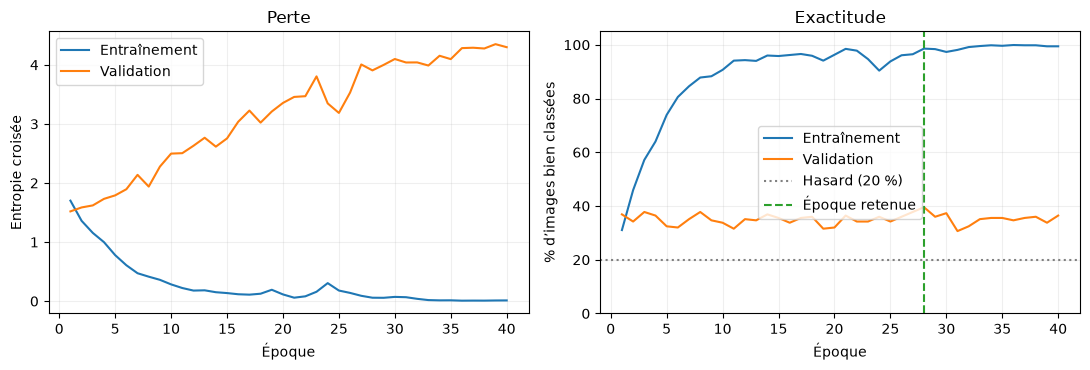

In [24]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))

for split, label in (("train", "Entraînement"), ("validation", "Validation")):
    ax_loss.plot(history["epoch"], history[f"{split}_loss"], label=label)
    ax_acc.plot(history["epoch"], 100 * history[f"{split}_accuracy"], label=label)

ax_loss.set(title="Perte", xlabel="Époque", ylabel="Entropie croisée")
ax_acc.set(title="Exactitude", xlabel="Époque", ylabel="% d’images bien classées", ylim=(0, 105))
ax_acc.axhline(20, color="gray", linestyle=":", label="Hasard (20 %)")
ax_acc.axvline(summary["best_epoch"], color="tab:green", linestyle="--", label="Époque retenue")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


### Ce qu’on observe sur ce premier essai

Le MLP atteint **39,6 % sur la validation à l’époque 28**, contre **98,6 % à l’entraînement** à cette époque.
L’écart est d’environ **59 points**. Le score dépasse les 20 % attendus au hasard, mais reste loin des résultats d’entraînement.

La perte d’entraînement baisse presque jusqu’à zéro, alors que la perte de validation augmente.
L’exactitude de validation, elle, reste globalement dans la même zone.
Ces deux observations indiquent un surapprentissage marqué. Garder la meilleure époque évite de retenir les derniers poids,
mais ne règle pas ce problème.

Ce résultat concerne une seule seed. On n’a pas encore mesuré sa variabilité ni regardé quels styles sont les plus confondus.
On ne peut donc pas attribuer les erreurs à un style particulier, ni conclure qu’un petit gain serait significatif.


## 6. Étape 5 — limiter le surapprentissage du MLP

La référence précédente apprend presque parfaitement l’entraînement mais généralise mal.
On essaie ici de réduire cet écart en changeant une chose à la fois : un dropout de 0,3 dans les deux couches cachées,
un weight decay de 0,0001, puis les deux ensemble. Un cinquième essai reprend le MLP sans régularisation,
avec un arrêt après huit époques sans amélioration du checkpoint de validation.

On garde les mêmes images, le même découpage, la même seed, Adam et un maximum de 40 époques.
On relance aussi une référence dans l’environnement actuel : les versions des bibliothèques peuvent différer de celles
du premier essai, donc son score de 39,6 % ne suffit pas à isoler l’effet des changements.

Le dropout est désactivé lors de l’évaluation. Pour comparer les écarts correctement, on mesure aussi l’entraînement
en mode évaluation à chaque époque ; les mesures prises pendant les mises à jour sont conservées séparément.


In [25]:
REGULARIZATION_DIR = ROOT / "outputs/mlp_regularization"
MLP_EXPERIMENTS = [
    {"name": "reference", "dropout": 0.0, "weight_decay": 0.0, "patience": None},
    {"name": "dropout", "dropout": 0.3, "weight_decay": 0.0, "patience": None},
    {"name": "weight_decay", "dropout": 0.0, "weight_decay": 1e-4, "patience": None},
    {"name": "dropout_weight_decay", "dropout": 0.3, "weight_decay": 1e-4, "patience": None},
    {"name": "early_stopping", "dropout": 0.0, "weight_decay": 0.0, "patience": 8},
]

class RegularizedMLP(nn.Module):
    def __init__(self, num_classes, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * INPUT_SIZE * INPUT_SIZE, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        return self.layers(images)

pd.DataFrame(MLP_EXPERIMENTS).set_index("name")


,dropout,weight_decay,patience
name,,,
reference,0.0,0.0000,NaN
dropout,0.3,0.0000,NaN
weight_decay,0.0,0.0001,NaN
dropout_weight_decay,0.3,0.0001,NaN
early_stopping,0.0,0.0000,8.0


### Un protocole commun

Un checkpoint s’améliore si son exactitude de validation augmente, ou si sa perte baisse à exactitude égale.
Ce même critère remet le compteur d’arrêt anticipé à zéro. Les autres essais vont jusqu’à 40 époques.
On sauvegarde l’historique, les poids retenus et la matrice de confusion de validation de chaque essai.
Aucun chargeur d’images de test n’est créé.


In [26]:
def checkpoint_improves(accuracy, loss, best_accuracy, best_loss):
    return accuracy > best_accuracy or (accuracy == best_accuracy and loss < best_loss)


def fit_experiment(model, experiment_loaders, *, epochs, learning_rate, weight_decay,
                   patience, seed, experiment_device):
    loss_function = nn.CrossEntropyLoss()
    optimizer = Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=learning_rate, weight_decay=weight_decay,
    )
    # Ce chargeur ne mélange pas les images et ne consomme pas le générateur des batches d’entraînement.
    train_eval = DataLoader(experiment_loaders["train"].dataset, batch_size=64, shuffle=False)
    records, best_state = [], None
    best_accuracy, best_loss, best_epoch, stale_epochs = -1.0, float("inf"), 0, 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        online_loss, online_accuracy = train_epoch(
            model, experiment_loaders["train"], loss_function, optimizer, experiment_device
        )
        train_loss, train_accuracy = validate_epoch(model, train_eval, loss_function, experiment_device)
        val_loss, val_accuracy = validate_epoch(
            model, experiment_loaders["validation"], loss_function, experiment_device
        )
        records.append({
            "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
            "validation_loss": val_loss, "validation_accuracy": val_accuracy,
            "online_train_loss": online_loss, "online_train_accuracy": online_accuracy,
            "learning_rate": learning_rate,
        })
        if checkpoint_improves(val_accuracy, val_loss, best_accuracy, best_loss):
            best_accuracy, best_loss, best_epoch, stale_epochs = val_accuracy, val_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale_epochs += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"  époque {epoch:02d} : train {train_accuracy:.1%}, validation {val_accuracy:.1%}", flush=True)
        if patience is not None and stale_epochs >= patience:
            print(f"  arrêt à l’époque {epoch} : {patience} époques sans amélioration", flush=True)
            break

    model.load_state_dict(best_state)
    return records, {
        "epochs_run": len(records), "best_epoch": best_epoch,
        "best_validation_accuracy": best_accuracy, "best_validation_loss": best_loss,
        "train_accuracy_at_best_epoch": records[best_epoch - 1]["train_accuracy"],
        "train_validation_accuracy_gap": records[best_epoch - 1]["train_accuracy"] - best_accuracy,
        "stopped_early": len(records) < epochs, "training_seconds": time.perf_counter() - started,
    }


@torch.inference_mode()
def validation_confusion(model, loader, num_classes, experiment_device):
    model.eval()
    matrix = torch.zeros((num_classes, num_classes), dtype=torch.long)
    for images, labels in loader:
        predictions = model(images.to(experiment_device)).argmax(dim=1).cpu()
        matrix += torch.bincount(labels * num_classes + predictions, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return matrix


def save_experiment(model, records, result, folder, configuration, classes, matrix, extra_checkpoint=None):
    import torchvision
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = folder / "checkpoints"
    checkpoint_dir.mkdir(exist_ok=True)
    checkpoint = checkpoint_dir / "best.pt"
    torch.save({
        "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "class_names": classes, "config": configuration,
        "best_epoch": result["best_epoch"], **(extra_checkpoint or {}),
    }, checkpoint)
    pd.DataFrame(records).to_csv(folder / "training_history.csv", index=False)
    pd.DataFrame(matrix.tolist(), index=classes, columns=classes).rename_axis("true_style").to_csv(
        folder / "validation_confusion.csv"
    )
    result.update({
        "config": configuration, "class_names": classes, "test_evaluated": False,
        "checkpoint": checkpoint.relative_to(ROOT).as_posix(),
        "manifest": MANIFEST_PATH.relative_to(ROOT).as_posix(),
        "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
        "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "python": sys.version.split()[0]},
    })
    (folder / "validation_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def run_mlp_experiments():
    experiment_device = choose_device(MLP_CONFIG.device)
    for settings in MLP_EXPERIMENTS:
        print("Essai :", settings["name"], flush=True)
        set_seed(SEED)
        experiment_loaders, classes, _, _ = read_training_rows(DATA_DIR, MANIFEST_PATH, SEED, 0, 64)
        model = RegularizedMLP(len(classes), settings["dropout"]).to(experiment_device)
        records, result = fit_experiment(
            model, experiment_loaders, epochs=40, learning_rate=1e-3,
            weight_decay=settings["weight_decay"], patience=settings["patience"],
            seed=SEED, experiment_device=experiment_device,
        )
        result.update({"model": "Regularized MLP", "device": str(experiment_device),
                       "parameter_count": sum(p.numel() for p in model.parameters())})
        matrix = validation_confusion(model, experiment_loaders["validation"], len(classes), experiment_device)
        configuration = {**settings, "seed": SEED, "epochs": 40, "learning_rate": 1e-3,
                         "batch_size": 64, "input_size": 64, "normalization_mean": NORMALIZE_MEAN,
                         "normalization_std": NORMALIZE_STD,
                         "checkpoint_selection": "validation accuracy, then validation loss",
                         "train_metrics": "eval mode after each epoch"}
        save_experiment(model, records, result, REGULARIZATION_DIR / settings["name"], configuration, classes, matrix)
        print(f"  meilleur checkpoint : {result['best_validation_accuracy']:.1%} à l’époque {result['best_epoch']}", flush=True)

if RUN_REGULARIZATION:
    run_mlp_experiments()


In [27]:
mlp_results = {}
for settings in MLP_EXPERIMENTS:
    result_path = REGULARIZATION_DIR / settings["name"] / "validation_summary.json"
    if not result_path.is_file():
        raise FileNotFoundError("Résultats de régularisation absents : passer RUN_REGULARIZATION = True.")
    mlp_results[settings["name"]] = json.loads(result_path.read_text(encoding="utf-8"))

mlp_comparison = pd.DataFrame([
    {"Essai": name, "Époques": result["epochs_run"], "Meilleure époque": result["best_epoch"],
     "Train (%)": 100 * result["train_accuracy_at_best_epoch"],
     "Validation (%)": 100 * result["best_validation_accuracy"],
     "Écart (points)": 100 * result["train_validation_accuracy_gap"],
     "Perte validation": result["best_validation_loss"]}
    for name, result in mlp_results.items()
]).set_index("Essai")
mlp_comparison.round(2)


,Époques,Meilleure époque,Train (%),Validation (%),Écart (points),Perte validation
Essai,,,,,,
reference,40,40,98.38,39.56,58.83,4.53
dropout,40,27,90.95,42.22,48.73,2.63
weight_decay,40,8,86.67,38.22,48.44,1.98
dropout_weight_decay,40,3,49.33,39.56,9.78,1.46
early_stopping,11,3,64.95,37.78,27.17,1.62


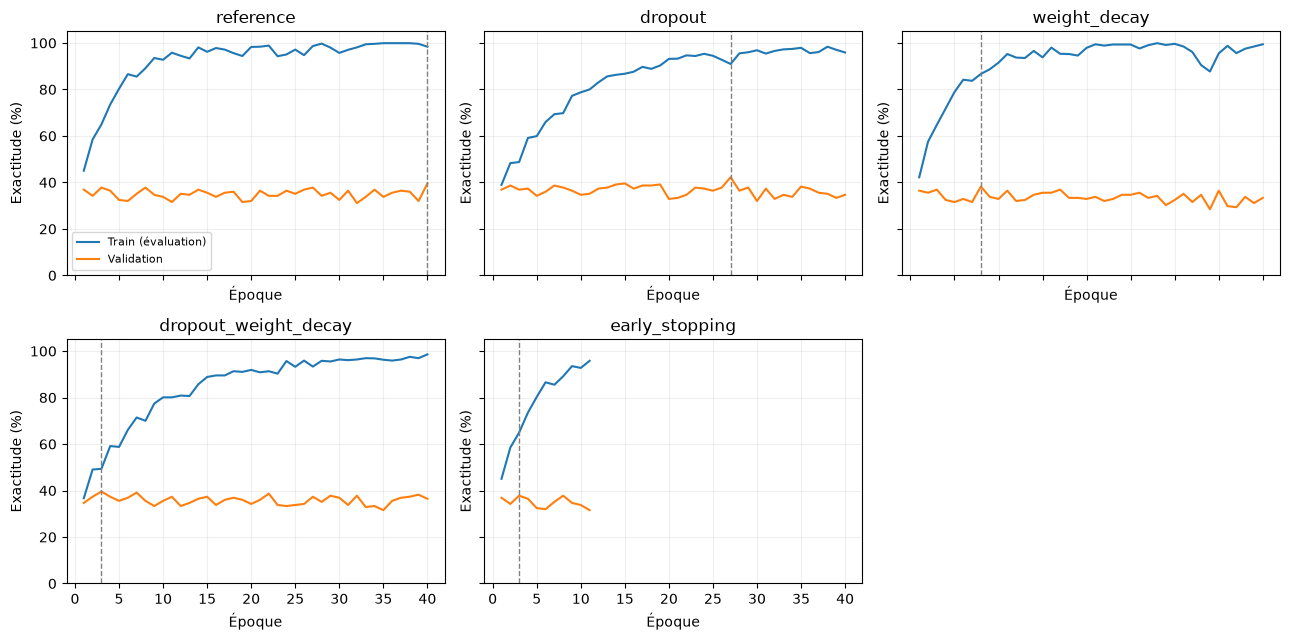

MLP retenu avec la validation : dropout


In [28]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, (name, result) in zip(axes.flat, mlp_results.items()):
    run_history = pd.read_csv(REGULARIZATION_DIR / name / "training_history.csv")
    ax.plot(run_history["epoch"], 100 * run_history["train_accuracy"], label="Train (évaluation)")
    ax.plot(run_history["epoch"], 100 * run_history["validation_accuracy"], label="Validation")
    ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Époque", ylabel="Exactitude (%)", ylim=(0, 105))
    ax.grid(alpha=0.2)
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

best_mlp_name = max(mlp_results, key=lambda name: (
    mlp_results[name]["best_validation_accuracy"], -mlp_results[name]["best_validation_loss"]
))
print("MLP retenu avec la validation :", best_mlp_name)


### Ce que changent ces essais

Le meilleur MLP de cette comparaison est celui avec **dropout : 42,2 % en validation à l’époque 27**,
contre 39,6 % pour la référence relancée. Cela représente six images bien classées de plus sur 225.
Son score d’entraînement, mesuré en mode évaluation à cette époque, reste de 91,0 % :
l’écart est encore de **48,7 points**, contre 58,8 pour la référence. Le surapprentissage reste donc important.

Le weight decay seul donne 38,2 %. La combinaison dropout + weight decay atteint 39,6 % dès l’époque 3,
avec seulement 49,3 % sur l’entraînement à cette époque. Son petit écart ne suffit pas à en faire un meilleur modèle :
les deux scores sont faibles. L’arrêt anticipé s’arrête à l’époque 11 et retient l’époque 3, à 37,8 %.
Avec cette patience de huit époques, il manque des améliorations plus tardives observées sur la référence.

On garde le dropout comme **candidat MLP pour la suite**, sur le critère fixé de validation.
On a essayé plusieurs réglages sur la même petite validation et une seule seed : le gain de 2,7 points ne constitue pas
à lui seul une preuve de supériorité reproductible. Aucun score de test n’a été calculé.


### Quels styles restent difficiles pour le MLP ?

Voici la matrice du MLP retenu, toujours sur la validation. Les lignes sont les vrais styles.
Cubism reste particulièrement difficile : trois images sur 45 sont correctement reconnues,
avec des prédictions fréquentes vers Baroque (14) et Ukiyo-e (13).


In [29]:
mlp_confusion = pd.read_csv(
    REGULARIZATION_DIR / best_mlp_name / "validation_confusion.csv", index_col=0
)
display(mlp_confusion)
mlp_recall = 100 * pd.Series(
    mlp_confusion.values.diagonal() / mlp_confusion.sum(axis=1).values,
    index=mlp_confusion.index, name="Exactitude validation (%)",
)
mlp_recall.round(1).to_frame()


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
true_style,,,,,
Baroque,32,2,5,2,4
Cubism,14,3,8,7,13
Impressionism,17,2,14,4,8
Pop_Art,9,4,5,17,10
Ukiyo_e,4,1,7,4,29


,Exactitude validation (%)
true_style,
Baroque,71.1
Cubism,6.7
Impressionism,31.1
Pop_Art,37.8
Ukiyo_e,64.4


## 7. Étape 6 — réutiliser un ResNet préentraîné

Le MLP part de pixels et apprend tous ses poids sur seulement 1 050 images.
On essaie maintenant **ResNet-18 avec ses poids ImageNet**, en remplaçant sa dernière couche par cinq sorties.
Toutes les autres couches sont gelées. Elles restent aussi en mode évaluation : les statistiques de BatchNorm
ne doivent pas changer pendant que l’on entraîne la tête.

Les [poids de torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
ont leur propre préparation : redimensionnement à 256, recadrage à 224 et normalisation ImageNet.
Nos fichiers font déjà 128 × 128 : les agrandir n’ajoute pas de détails.
Une différence avec le MLP mélange donc ici le préentraînement, l’architecture et la préparation des images.

Comme le corps du réseau ne change pas et qu’il n’y a pas d’augmentation aléatoire, on calcule ses caractéristiques
une seule fois pour train et validation. La petite couche finale s’entraîne ensuite sur ces vecteurs de 512 valeurs.
Cela correspond au principe d’[extraction de caractéristiques de PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial).


In [30]:
from torch.utils.data import TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

RESNET_DIR = ROOT / "outputs/resnet18_head"
RESNET_CONFIG = {
    "name": "resnet18_head", "weights": "ResNet18_Weights.IMAGENET1K_V1",
    "seed": SEED, "epochs": 60, "learning_rate": 1e-3, "weight_decay": 1e-4,
    "batch_size": 64, "extraction_batch_size": 32, "patience": 10,
    "trainable_layers": ["fc"], "feature_size": 512,
    "checkpoint_selection": "validation accuracy, then validation loss",
}
RESNET_CONFIG


{'name': 'resnet18_head',
 'weights': 'ResNet18_Weights.IMAGENET1K_V1',
 'seed': 42,
 'epochs': 60,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'batch_size': 64,
 'extraction_batch_size': 32,
 'patience': 10,
 'trainable_layers': ['fc'],
 'feature_size': 512,
 'checkpoint_selection': 'validation accuracy, then validation loss'}

### Geler le réseau et préparer les caractéristiques

On utilise exactement les mêmes chemins et étiquettes que pour le MLP. Les images de test ne sont pas chargées.
On vérifie le nombre de paramètres entraînables et l’empreinte du corps du réseau avant et après l’expérience,
pour s’assurer que seules les valeurs de la couche finale ont changé.


In [31]:
def backbone_digest(model):
    digest = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        if not name.startswith("fc."):
            digest.update(name.encode())
            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


@torch.no_grad()
def extract_features(extractor, dataset, batch_size, extraction_device):
    extractor.eval()
    features, targets = [], []
    for images, labels in DataLoader(dataset, batch_size=batch_size, shuffle=False):
        features.append(extractor(images.to(extraction_device)).cpu())
        targets.append(labels)
    return TensorDataset(torch.cat(features), torch.cat(targets))


def run_resnet_head():
    set_seed(SEED)
    experiment_device = choose_device(MLP_CONFIG.device)
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)
    model.requires_grad_(False)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model = model.to(experiment_device)
    model.eval()
    before_digest = backbone_digest(model)
    assert all(not p.requires_grad for name, p in model.named_parameters() if not name.startswith("fc."))
    assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 2565

    # On réutilise les lignes déjà sélectionnées, sans construire de jeu de test.
    image_datasets = {
        split: ManifestImageDataset(DATA_DIR, loaders[split].dataset.records, weights.transforms())
        for split in ("train", "validation")
    }
    extractor = nn.Sequential(*list(model.children())[:-1], nn.Flatten()).to(experiment_device)
    extraction_start = time.perf_counter()
    feature_datasets = {}
    for split, dataset in image_datasets.items():
        print("Extraction :", split, len(dataset), "images", flush=True)
        feature_datasets[split] = extract_features(
            extractor, dataset, RESNET_CONFIG["extraction_batch_size"], experiment_device
        )
    extraction_seconds = time.perf_counter() - extraction_start
    assert not any(module.training for module in extractor.modules())
    generator = torch.Generator().manual_seed(SEED)
    feature_loaders = {
        split: DataLoader(dataset, batch_size=RESNET_CONFIG["batch_size"],
                          shuffle=(split == "train"), generator=generator if split == "train" else None)
        for split, dataset in feature_datasets.items()
    }
    print("Paramètres entraînables :", sum(p.numel() for p in model.parameters() if p.requires_grad), flush=True)
    records, result = fit_experiment(
        model.fc, feature_loaders, epochs=RESNET_CONFIG["epochs"],
        learning_rate=RESNET_CONFIG["learning_rate"], weight_decay=RESNET_CONFIG["weight_decay"],
        patience=RESNET_CONFIG["patience"], seed=SEED, experiment_device=experiment_device,
    )
    after_digest = backbone_digest(model)
    assert before_digest == after_digest, "Les paramètres ou statistiques du corps gelé ont changé."
    matrix = validation_confusion(model.fc, feature_loaders["validation"], len(class_names), experiment_device)
    preprocessing = weights.transforms()
    result.update({
        "model": "ResNet-18 frozen backbone + linear head", "device": str(experiment_device),
        "parameter_count": sum(p.numel() for p in model.parameters()),
        "trainable_parameter_count": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "feature_extraction_seconds": extraction_seconds,
        "backbone_sha256_before": before_digest, "backbone_sha256_after": after_digest,
        "backbone_unchanged": before_digest == after_digest,
        "split_counts": {split: len(dataset) for split, dataset in image_datasets.items()},
        "feature_shapes": {split: list(dataset.tensors[0].shape) for split, dataset in feature_datasets.items()},
        "preprocessing": {"resize": preprocessing.resize_size, "crop": preprocessing.crop_size,
                          "mean": preprocessing.mean, "std": preprocessing.std},
    })
    save_experiment(model, records, result, RESNET_DIR, RESNET_CONFIG, class_names, matrix,
                    extra_checkpoint={"preprocessing": result["preprocessing"]})
    print(f"Meilleure validation : {result['best_validation_accuracy']:.1%} à l’époque {result['best_epoch']}", flush=True)

if RUN_RESNET_HEAD:
    run_resnet_head()


In [32]:
resnet_summary_path = RESNET_DIR / "validation_summary.json"
if not resnet_summary_path.is_file():
    raise FileNotFoundError("Résultats ResNet absents : passer RUN_RESNET_HEAD = True.")
resnet_result = json.loads(resnet_summary_path.read_text(encoding="utf-8"))
resnet_history = pd.read_csv(RESNET_DIR / "training_history.csv")
print("Paramètres entraînables :", resnet_result["trainable_parameter_count"])
print("Corps du réseau inchangé :", resnet_result["backbone_unchanged"])
print(f"Extraction des caractéristiques : {resnet_result['feature_extraction_seconds']:.1f} s")
print(f"Entraînement de la tête : {resnet_result['training_seconds']:.1f} s")
print("Meilleure époque :", resnet_result["best_epoch"])
print(f"Exactitude train : {resnet_result['train_accuracy_at_best_epoch']:.1%}")
print(f"Exactitude validation : {resnet_result['best_validation_accuracy']:.1%}")
print("Test évalué :", resnet_result["test_evaluated"])


Paramètres entraînables : 2565
Corps du réseau inchangé : True
Extraction des caractéristiques : 5.2 s
Entraînement de la tête : 1.3 s
Meilleure époque : 16
Exactitude train : 87.9%
Exactitude validation : 75.6%
Test évalué : False


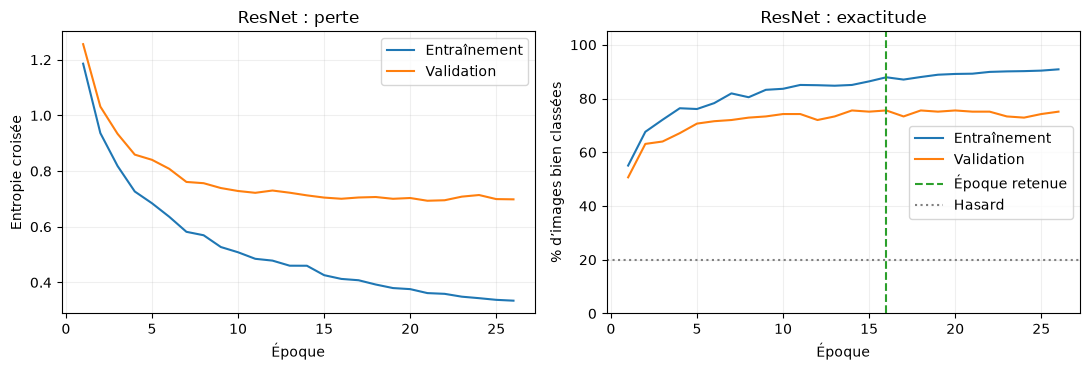

In [33]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
for split, label in (("train", "Entraînement"), ("validation", "Validation")):
    ax_loss.plot(resnet_history["epoch"], resnet_history[f"{split}_loss"], label=label)
    ax_acc.plot(resnet_history["epoch"], 100 * resnet_history[f"{split}_accuracy"], label=label)
ax_loss.set(title="ResNet : perte", xlabel="Époque", ylabel="Entropie croisée")
ax_acc.set(title="ResNet : exactitude", xlabel="Époque", ylabel="% d’images bien classées", ylim=(0, 105))
ax_acc.axvline(resnet_result["best_epoch"], color="tab:green", linestyle="--", label="Époque retenue")
ax_acc.axhline(20, color="gray", linestyle=":", label="Hasard")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


### Quels styles sont confondus ?

Les lignes donnent les vrais styles et les colonnes les prédictions. La diagonale correspond aux bonnes réponses.
Ces résultats portent sur les 225 images de validation.


In [34]:
resnet_confusion = pd.read_csv(RESNET_DIR / "validation_confusion.csv", index_col=0)
display(resnet_confusion)
per_style = 100 * pd.Series(
    resnet_confusion.values.diagonal() / resnet_confusion.sum(axis=1).values,
    index=resnet_confusion.index, name="Exactitude validation (%)",
)
display(per_style.round(1).to_frame())

pd.DataFrame({
    "Modèle": [f"MLP ({best_mlp_name})", "ResNet-18, tête seule"],
    "Validation (%)": [100 * mlp_results[best_mlp_name]["best_validation_accuracy"],
                        100 * resnet_result["best_validation_accuracy"]],
    "Paramètres entraînables": [mlp_results[best_mlp_name]["parameter_count"],
                                resnet_result["trainable_parameter_count"]],
}).set_index("Modèle").round(2)


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
true_style,,,,,
Baroque,35,2,5,1,2
Cubism,1,33,1,8,2
Impressionism,6,1,36,2,0
Pop_Art,2,8,5,26,4
Ukiyo_e,0,2,3,0,40


,Exactitude validation (%)
true_style,
Baroque,77.8
Cubism,73.3
Impressionism,80.0
Pop_Art,57.8
Ukiyo_e,88.9


,Validation (%),Paramètres entraînables
Modèle,,
MLP (dropout),42.22,3179525
"ResNet-18, tête seule",75.56,2565


### Ce qu’on observe avec les caractéristiques ImageNet

La tête du ResNet obtient **75,6 % sur la validation** (170 images sur 225) à l’époque 16.
À cette époque, l’exactitude d’entraînement est de 87,9 %, soit un écart de **12,3 points**.
L’arrêt anticipé met fin à l’essai à l’époque 26. Seuls **2 565 paramètres** sont entraînés ;
l’empreinte du corps du réseau est identique avant et après l’expérience, statistiques de BatchNorm comprises.

Le score dépasse de 33,3 points celui du MLP avec dropout sur ce découpage.
Les caractéristiques préentraînées sont donc un point de départ prometteur ici.
On ne peut pas isoler l’effet du préentraînement dans ce seul essai : l’architecture et la préparation des images changent aussi.

Tous les styles ne sont pas aussi bien reconnus : **Ukiyo-e atteint 88,9 %**, contre **57,8 % pour Pop Art**.
Pop Art et Cubism sont confondus huit fois dans chaque sens. La matrice montre où regarder ; elle ne dit pas encore
quels détails visuels expliquent ces erreurs.

Cela ne permet pas encore de choisir le modèle des bornes. Le ResNet conserve plus de onze millions de paramètres au total,
même si seule sa tête a été entraînée. Il reste à mesurer sa latence sur CPU et à le comparer au modèle classique.
L’évaluation finale sur le test reste à faire après la sélection.


## 8. La suite

Le prochain essai sera d’affiner `layer4` du ResNet avec un taux d’apprentissage plus faible.
Il faudra ensuite entraîner la régression logistique et comparer les modèles choisis avec la validation,
puis mesurer leur score final, leur latence CPU et leur taille.
Le temps d’entraînement de la tête seule ne représente pas la latence d’un ResNet complet en production.

| Étape | Où on en est |
|---|---|
| Sous-ensemble et découpage | Faits ; manifeste et rapport dans `manifests/` |
| MLP de référence | Entraîné, courbes et diagnostic disponibles |
| Régularisation du MLP | Cinq essais réalisés, checkpoints choisis avec la validation |
| ResNet : tête seule | Entraînée, corps gelé vérifié |
| ResNet : affiner `layer4` | À faire |
| Modèle classique et comparaison finale | À faire |

La séparation par artiste reste imparfaite, les expériences n’utilisent qu’une seed et la validation ne contient que
225 images. On garde ces limites pour l’interprétation ; le test n’a servi ni à l’entraînement ni au choix des modèles.
Le rendu comprend aussi une présentation de 10 minutes suivie de 5 minutes de questions.
La recherche d’œuvres en langage naturel reste une piste ultérieure.


---

<details>
<summary>Énoncé original du projet</summary>

You are a member of the AI team of a (fictional) mid-sized French fine-arts museum (the Museum below). The Museum wants an intelligent guide, available on visitors' phones and on kiosks in the galleries, that can do two things

1.  Recognise what the visitor is looking at. The visitor points the camera at a painting; the guide recognises its style (Impressionism, Baroque, Cubism…) or its genre (portrait, landscape, still life…) and tells the story of that movement or tradition.

2.  Answer questions in natural language. A visitor types "Which painting shows a stormy sea?" or "I would like to see portraits of children"; the guide proposes the artworks of the collection that best match the question.

The director also expects a clear recommendation: the kiosks run on modest CPUs, the team is small and the budget is limited. Is a neural network worth it in production, or would a simpler classical model do the job?
Your mission is to build, diagnose and defend the neural-network components of this guide, in the spirit of the course: networks built from PyTorch primitives rather than library magic, every number measured, every claim backed by evidence. The project is mutualised: the scenario and the assessment format (Git deliverable, group oral defence, individual deliberation, peer review) are shared at programme level

DATA : Can be loaded from the attached Python File


DELIVERABLE : 
- A feed-forward network in PyTorch for artwork classification
-  Training monitoring and failure diagnosis
- A pretrained CNN (ResNet) for image classification

Deadline : 30th October


The Source Code must be delivered with Clear Git History on Github or Gitlab.

You will also need to prepare a 10 minutes PowerPoint Presentation followed by a 5 Minutes Q&A.

</details>
